# 加载模型及简要总结

## 鲁棒性分析 (厌氧)
### 生长
设置底物吸收速度间隔为 1 mmol/gDW/h, 从 0 到 70 mmol/gDW/h,计算每个底物吸收速率值对应的菌株生长最优值.

In [1]:
import sys
sys.path.append(r'./ETGEM/etgems_web/')
import ETGEM.etgems_web.script
from ETGEM.etgems_web.script.io.json import *
from ETGEM.etgems_web.script.tcmodel.construct import get_K_value
from ETGEM.etgems_web.script.plotting.plotting import *
import numpy as np
from ETGEM.etgems_web.script.analysis.flux_balance_analysis import *
from ETGEM.etgems_web.script.analysis.max_driving_force import *
from ETGEM.etgems_web.script.ecmpy.ECMpy_function import *


cobra.Configuration.solver="gurobi"
model_iZM4_478 = cobra.io.read_sbml_model("./iZM4_478-pcbi.1008137.s002.xml")
model_iZM516 = cobra.io.read_sbml_model("./Supplementary_file_1_iZM516.sbml")
model_eciZM547 = get_enzyme_constraint_model('./eciZM547.json')
model_etiZM564 = read_json_model("./model/ETiZM564_MM_optimized.json")

print(f"{'Model':<10} | {'Genes':>7} | {'Reactions':>9} | {'Metabolites':>11}")
print("-" * 55)
# 四个模型一行展示
print(f"iZM4_478   | {len(model_iZM4_478.genes):>7d} | {len(model_iZM4_478.reactions):>9d} | {len(model_iZM4_478.metabolites):>11d}")
print(f"iZM516     | {len(model_iZM516.genes):>7d} | {len(model_iZM516.reactions):>9d} | {len(model_iZM516.metabolites):>11d}")
print(f"eciZM547   | {len(model_eciZM547.genes):>7d} | {len(model_eciZM547.reactions):>9d} | {len(model_eciZM547.metabolites):>11d}")
print(f"etiZM564   | {len(model_etiZM564.genes):>7d} | {len(model_etiZM564.reactions):>9d} | {len(model_etiZM564.metabolites):>11d}")
print("-" * 55)

# reaction_list,metabolite_list,lb_list,ub_list,coef_matrix,reaction_g0_list,reaction_kcat_MW_list,metabolites_lnC_list = Get_Model_Data(model)
# # reaction_kcat_MW = pd.DataFrame.from_dict(reaction_kcat_MW_list, orient='index')
# # reaction_kcat_MW.columns = ["kcat_MW"]
# print(reaction_kcat_MW_list)
# import datetime
# from ETGEM.etgems_web.script.ecmpy.ECMpy_function import *
# from ETGEM.etgems_web.script.ecmpy.AutoPACMEN_function import *
# cobra_config = cobra.Configuration()
# model_json = json_load("./model/iZM564_irr_enz_constraint_adj_final.json")
# for i in model_json['reactions']:
#     if i['kcat_MW'] != '' :
#         try:
#             if abs(round(float(i['kcat_MW']),4) - round(reaction_kcat_MW_list[i['id']],4))>1:
#                 print(i['id'],round(float(i['kcat_MW']),4),round(reaction_kcat_MW_list[i['id']],4),'\n')
#         except:
#             print(i)

Set parameter LicenseID to value 2845745
Model      |   Genes | Reactions | Metabolites
-------------------------------------------------------
iZM4_478   |     479 |       857 |         799
iZM516     |     516 |      1389 |        1437
eciZM547   |     547 |      2501 |        1455
etiZM564   |     564 |      2915 |        1641
-------------------------------------------------------


In [2]:
biomass_478,biomass_iZM516,biomass_eciZM547, biomass_etiZM564 = [],[],[],[]
sub = []

model_iZM4_478.reactions.get_by_id("EX_glc_e").bounds = (-1000,1000)
model_iZM4_478.reactions.get_by_id("BIOMASS_ZM").bounds = (0,1000)
# for g in np.arange(0,85,1):
for g in np.arange(0,81,1):
    sub.append(g)
    model_iZM4_478.objective = 'BIOMASS_ZM'   
    with model_iZM4_478:
        try:
            medium_478 = model_iZM4_478.medium
            medium_478['EX_glc_e'] = g
            medium_478['EX_o2_e'] = 0
            medium_478['EX_nh4_e'] = 1000
            medium_478['EX_n2_e'] = 0
            model_iZM4_478.medium = medium_478
            # pfba_solution = cobra.flux_analysis.pfba(model2)
            fba_solution = model_iZM4_478.optimize()
            biomass_478.append(fba_solution.fluxes['BIOMASS_ZM'])
        except:
            biomass_478.append(0)
    
    model_iZM516.objective = 'ZM_BIOMASS'
    with model_iZM516:
        medium_iZM516 = model_iZM516.medium
        medium_iZM516['EX_glc_D_e'] = g
        medium_iZM516['EX_o2_e'] = 0
        medium_iZM516['EX_nh4_e'] = 1000
        medium_iZM516['EX_n2_e'] = 0
        model_iZM516.medium = medium_iZM516
        fba_solution = model_iZM516.optimize()
        biomass_iZM516.append(fba_solution.fluxes['ZM_BIOMASS'])
        

    model_eciZM547.objective = 'ZM_BIOMASS'
    with model_eciZM547:
        medium_eciZM547 = model_eciZM547.medium
        medium_eciZM547['EX_glc_D_e'] = 0
        medium_eciZM547['EX_glc_D_e_reverse'] = g
        medium_eciZM547['EX_o2_e'] = 0
        medium_eciZM547['EX_nh4_e'] = 1000
        medium_eciZM547['EX_n2_e'] = 0
        model_eciZM547.medium = medium_eciZM547
        fba_solution = model_eciZM547.optimize()
        biomass_eciZM547.append(fba_solution.fluxes['ZM_BIOMASS'])

    model_etiZM564.obj_name = "ZM_BIOMASS"
    try:
        model_etiZM564.add_medium("EX_o2_e_reverse", 1000)
        model_etiZM564.get_reaction_by_id("EX_o2_e_reverse").bounds = (0, 1000)
        model_etiZM564.add_medium("EX_glc_D_e_reverse",g)
        opt_etm = calculate_ETM(model_etiZM564,"maximize",0.0)
        obj_enz_constraint = opt_etm.obj()
        biomass_etiZM564.append(opt_etm.obj())
    except:
        biomass_etiZM564.append(0)


d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cob

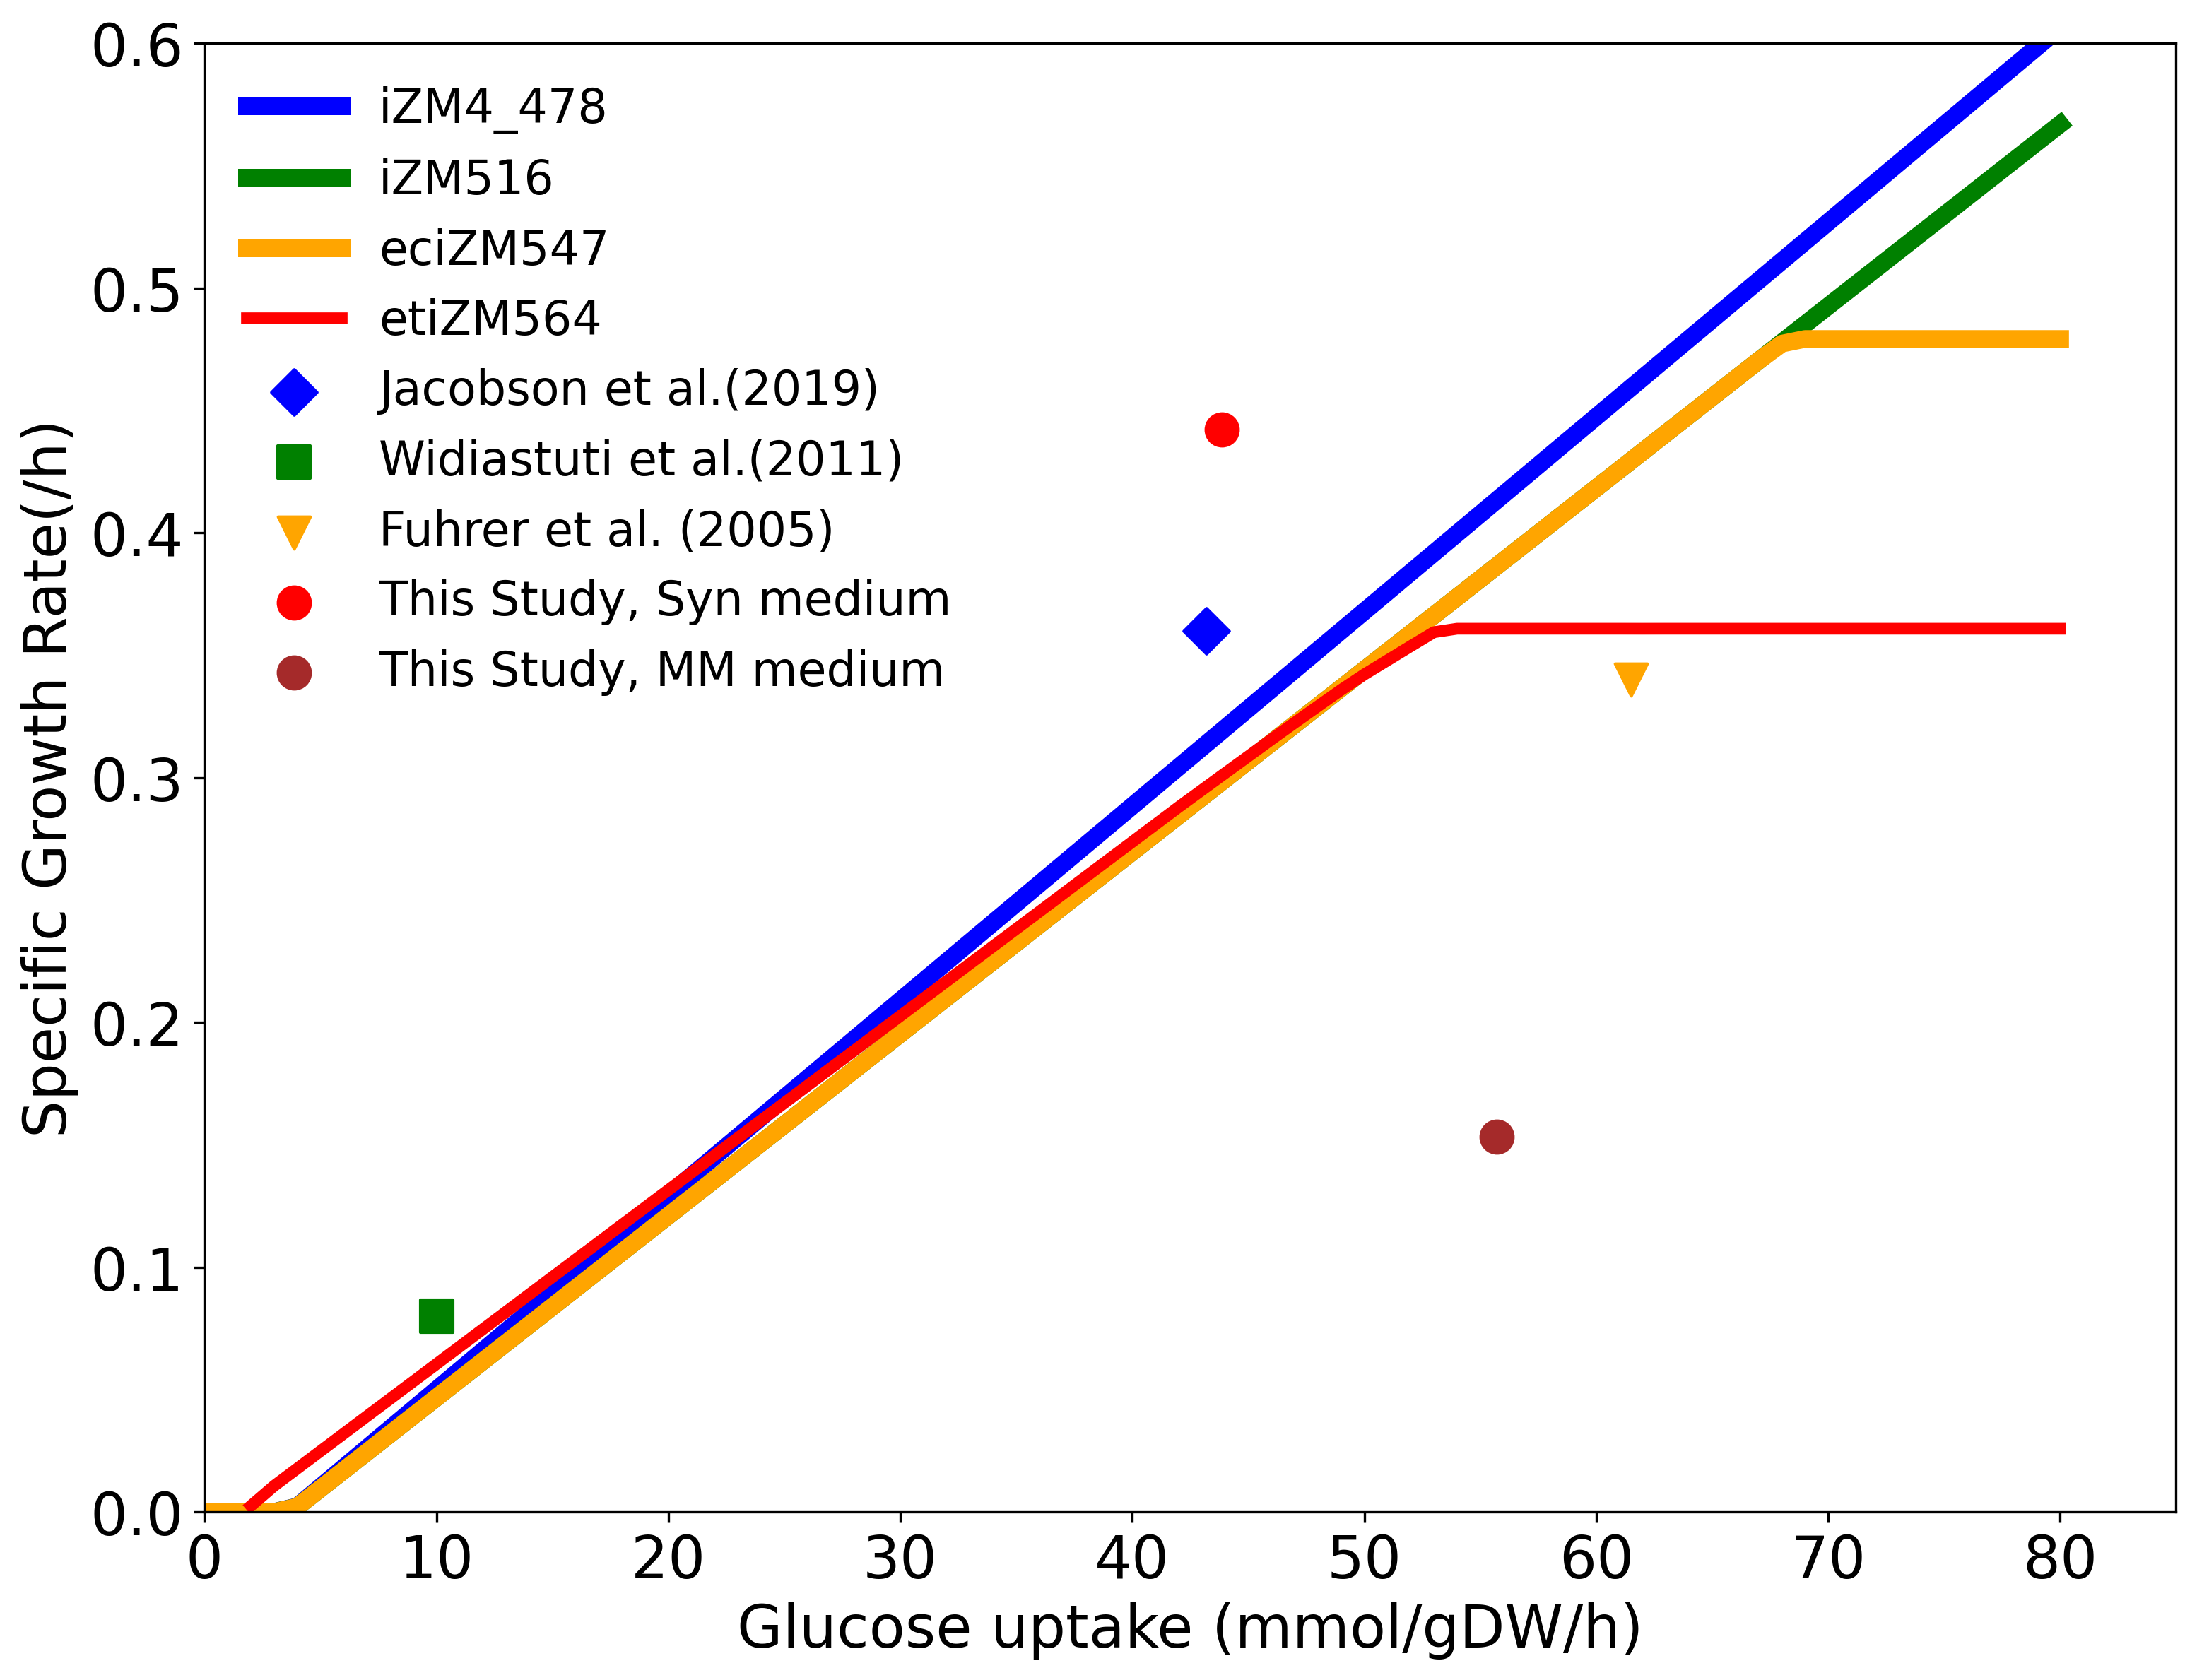

In [3]:
plt.figure(figsize=(12, 9),dpi=300)
ax = plt.gca() #获得当前的 Axes 对象 [get current axes]
plt.plot(sub,biomass_478, label="iZM4_478", linewidth=6, color='b',markersize=12)
plt.plot(sub,biomass_iZM516, label="iZM516", linewidth=6, color='g',markersize=12)
plt.plot(sub,biomass_eciZM547, label="eciZM547", linewidth=6, color='orange',markersize=12)
plt.plot(sub,biomass_etiZM564, label="etiZM564", linewidth=4, color='red',markersize=12)

marker_size=120
plt.scatter(43.2,0.36,marker='D',color = 'blue',label="Jacobson et al.(2019)", s=marker_size)
plt.scatter(10,0.08,marker='s',color = 'green',label="Widiastuti et al.(2011)", s=marker_size)
plt.scatter(61.5,0.34,marker='v',color = 'orange',label="Fuhrer et al. (2005)", s=marker_size)
plt.scatter(43.87,0.4422,color = 'red',label="This Study, Syn medium", s=marker_size)
plt.scatter(55.71,0.1533,color = 'brown',label="This Study, MM medium", s=marker_size)

fs = 20

x_min_tick = 0    # x轴最小tick
x_max_tick = np.ceil(max(sub))   # x轴最大tick
x_tick_step = 10   # x轴tick步长
plt.xticks(np.arange(x_min_tick, x_max_tick + 1, x_tick_step))  # 生成从最小到最大的tick，步长2

plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)
plt.xlabel("Glucose uptake (mmol/gDW/h)", fontsize=fs)
plt.ylabel("Specific Growth Rate(/h)", fontsize=fs)
plt.legend(loc=0, fontsize=fs-4,frameon=False) 
ax.set_ylim(0,0.6,0.05)  # biomass 小于 0 的不显示
ax.set_xlim(0,85)
plt.savefig('iZM564_iZM4_478_specific_Growth.png')
plt.savefig('iZM564_iZM4_478_specific_Growth.svg')
plt.show()

## 乙醇

In [4]:
iZM4_478_sub_biomass_dict = {}
iZM516_sub_biomass_dict = {}
eciZM547_sub_biomass_dict = {}
etiZM564_sub_biomass_dict = {}

for s in sub:
    iZM4_478_sub_biomass_dict[s] = biomass_478[s]
    iZM516_sub_biomass_dict[s] = biomass_iZM516[s]
    eciZM547_sub_biomass_dict[s] = biomass_eciZM547[s]
    etiZM564_sub_biomass_dict[s] = biomass_etiZM564[s]


In [5]:
sub_etoh = []

# 酒精生成
etoh_478 = []
etoh_iZM516 = []
etoh_eciZM547, etoh_etiZM564 = [],[]

model_iZM4_478.reactions.get_by_id("EX_glc_e").bounds = (-1000,1000)
for g in np.arange(0,81,1):
    sub_etoh.append(g)
    model_iZM4_478.objective = 'EX_etoh_e'    
    with model_iZM4_478:
        # model_iZM4_478.reactions.get_by_id("ATPM").bounds = (0,3.71)
        model_iZM4_478.reactions.get_by_id("BIOMASS_ZM").bounds = (iZM4_478_sub_biomass_dict[g],iZM4_478_sub_biomass_dict[g])
        medium_478 = model_iZM4_478.medium
        medium_478['EX_glc_e'] = g
        medium_478['EX_o2_e'] = 0
        medium_478['EX_nh4_e'] = 1000
        medium_478['EX_n2_e'] = 0
        model_iZM4_478.medium = medium_478
        # pfba_solution = cobra.flux_analysis.pfba(model2)
        fba_solution = model_iZM4_478.optimize()
        etoh_478.append(fba_solution.fluxes['EX_etoh_e'])
        # ac_e.append(fba_solution.fluxes['EX_ac_e0'])
        # lac_e.append(fba_solution.fluxes['EX_lac_D_e0'])
        # co2.append(fba_solution.fluxes['EX_co2_e0'])
     
    model_iZM516.objective = 'EX_etoh_e'
    with model_iZM516:
        model_iZM516.reactions.get_by_id("ZM_BIOMASS").bounds = (iZM516_sub_biomass_dict[g],iZM516_sub_biomass_dict[g])
        model_iZM516.reactions.get_by_id("EX_lac_D_e").knock_out()
        medium_iZM516 = model_iZM516.medium
        medium_iZM516['EX_glc_D_e'] = g
        medium_iZM516['EX_o2_e'] = 0
        medium_iZM516['EX_nh4_e'] = 1000
        medium_iZM516['EX_n2_e'] = 0
        model_iZM516.medium = medium_iZM516
        # pfba_solution = cobra.flux_analysis.pfba(model2)
        fba_solution = model_iZM516.optimize()
        etoh_iZM516.append(fba_solution.fluxes['EX_etoh_e'])
    
    model_eciZM547.objective = 'EX_etoh_e'
    with model_eciZM547:
        model_eciZM547.reactions.get_by_id("ZM_BIOMASS").bounds = (eciZM547_sub_biomass_dict[g],eciZM547_sub_biomass_dict[g])
        medium_eciZM547 = model_eciZM547.medium
        medium_eciZM547['EX_glc_D_e'] = 0
        medium_eciZM547['EX_glc_D_e_reverse'] = g
        medium_eciZM547['EX_o2_e'] = 0
        medium_eciZM547['EX_nh4_e'] = 1000
        medium_eciZM547['EX_n2_e'] = 0
        model_eciZM547.medium = medium_eciZM547
        fba_solution = model_eciZM547.optimize()
        etoh_eciZM547.append(fba_solution.fluxes['EX_etoh_e'])

    model_etiZM564.obj_name = "EX_etoh_e"
    model_etiZM564.add_medium("EX_glc_D_e_reverse",g)
    model_etiZM564.reactions["ZM_BIOMASS"].lower_bound = etiZM564_sub_biomass_dict[g]
    model_etiZM564.reactions["ZM_BIOMASS"].upper_bound= etiZM564_sub_biomass_dict[g]
    try:
        opt_etm = calculate_ETM(model_etiZM564,"maximize",0.0)
        obj_enz_constraint = opt_etm.obj()
        etoh_etiZM564.append(opt_etm.obj())
    except:
        etoh_etiZM564.append(0)


d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cobra\util\solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)
d:\Python\Python39\lib\site-packages\cob

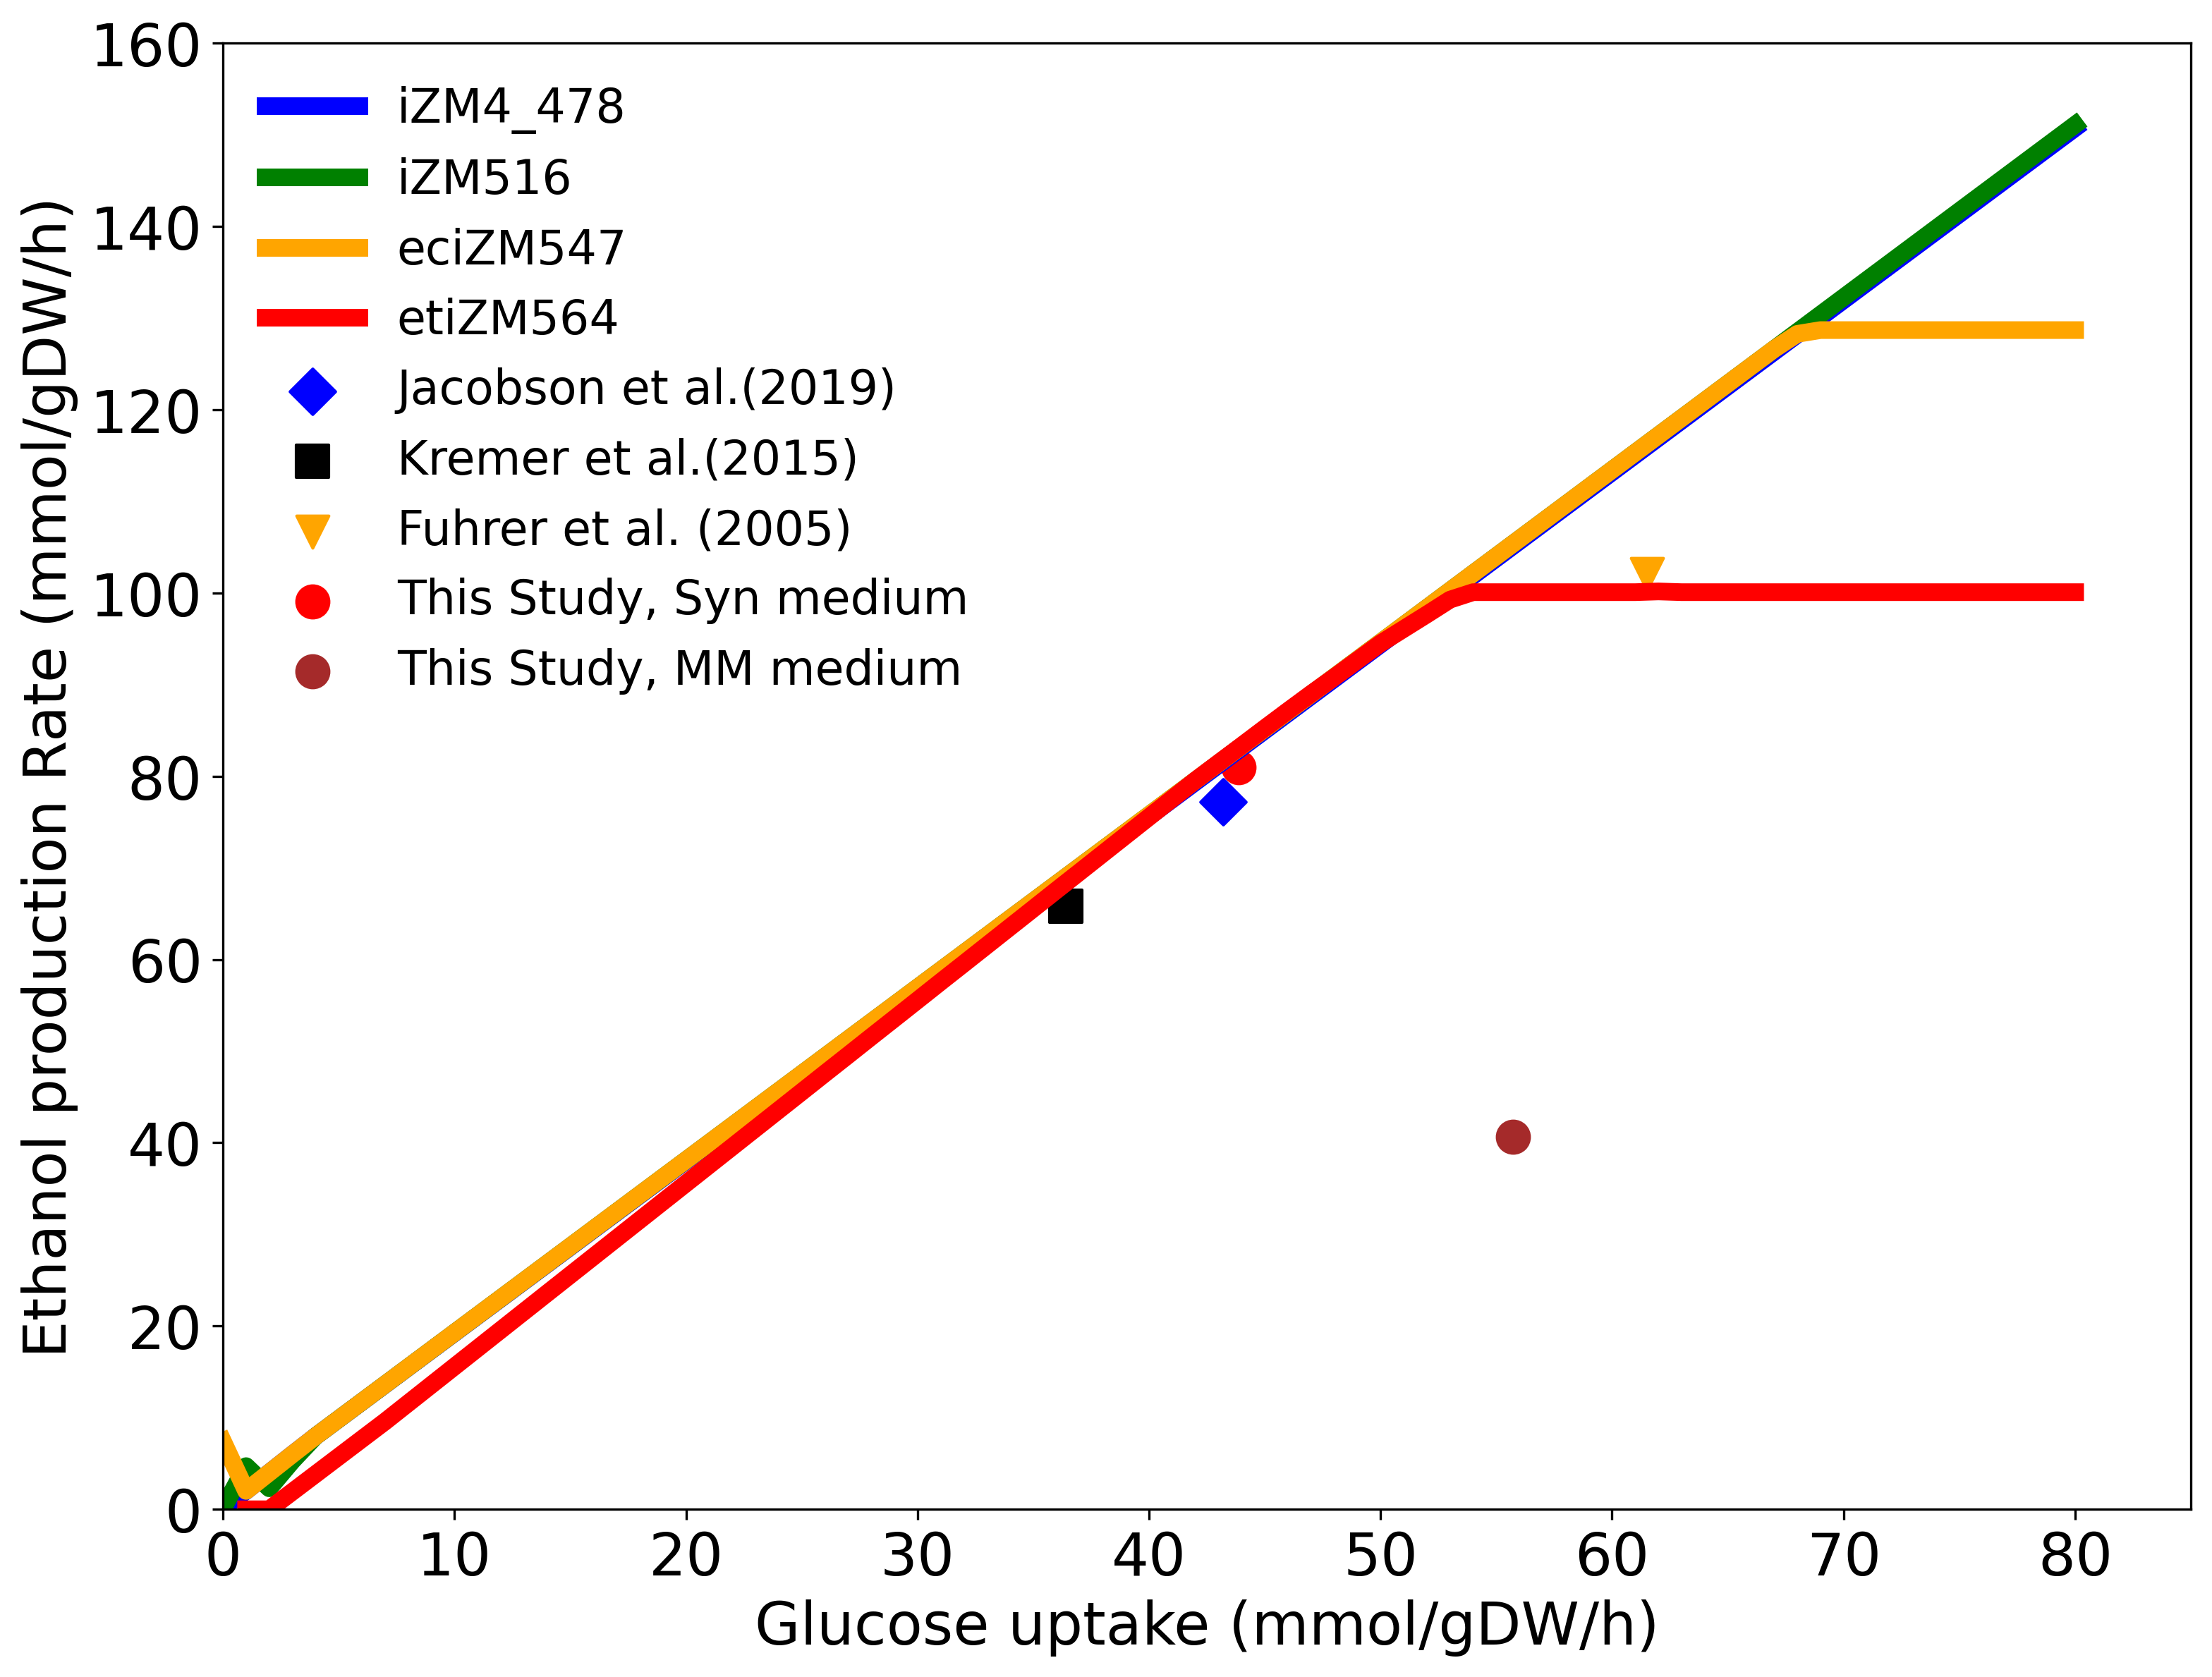

In [6]:
plt.figure(figsize=(12, 9),dpi=300)
ax = plt.gca() #获得当前的 Axes 对象 [get current axes]
plt.plot(sub_etoh,etoh_478, label="iZM4_478", linewidth=6, color='blue',markersize=12)
plt.plot(sub_etoh,etoh_iZM516, label="iZM516", linewidth=6, color='g',markersize=12)
plt.plot(sub_etoh,etoh_eciZM547, label="eciZM547", linewidth=6, color='orange',markersize=12)
x,y = zip(*[(a,b) for a,b in zip(sub_etoh,etoh_etiZM564) if a and b is not None])
plt.plot(x, y, label="etiZM564", linewidth=6, color='red', markersize=12)


plt.scatter(43.2,77.2,marker = 'D',label="Jacobson et al.(2019)", color = 'blue', s=marker_size)
plt.scatter(36.4,65.8,marker = 's',label="Kremer et al.(2015)", color = 'k', s=marker_size)
plt.scatter(61.5,102.1,marker = 'v',label="Fuhrer et al. (2005)", color = 'orange', s=marker_size)
plt.scatter(43.87,81.01,color = 'red',label="This Study, Syn medium", s=marker_size)
plt.scatter(55.71,40.66,color = 'brown',label="This Study, MM medium", s=marker_size)

#酒精生成，固氮时
# plt.scatter(51.0,97.2,marker = 'p',label="Kremer et al.(2015)")
fs = 20

x_min_tick = 0    # x轴最小tick
x_max_tick = np.ceil(max(sub_etoh))   # x轴最大tick
x_tick_step = 10   # x轴tick步长
plt.xticks(np.arange(x_min_tick, x_max_tick + 1, x_tick_step),fontsize=fs)  # 生成从最小到最大的tick，步长2
plt.yticks(fontsize=fs)
plt.xlabel("Glucose uptake (mmol/gDW/h)", fontsize=fs)
plt.ylabel("Ethanol production Rate (mmol/gDW/h)", fontsize=fs)
plt.legend(loc=0, fontsize=fs-4,frameon=False) 
ax.set_ylim(0,160)  # biomass 小于 0 的不显示
ax.set_xlim(0,85)
plt.savefig('iZM564_iZM4_478_Ethanol_production.png')
plt.savefig('iZM564_iZM4_478_Ethanol_production.svg')
plt.show()

In [7]:
# 提取酶热约束模型中所有通量
flux_var_candidates = []
print(dir(opt_etm))
# print(opt_etm)
# print(opt_etm.display())
# all_reaction_names = list(opt_etm.reaction_index)
# # print("所有反应列表：", all_reaction_names)

# # 2. 验证反应对象（确认反应是否存在）
# reaction_obj = opt_etm.reaction
# print("反应对象是否有效：", bool(reaction_obj))

# solve_results = opt_etm.solutions
# print("求解结果对象：", dir(solve_results))
# print(opt_etm.Df['EX_etoh_e'].value)
for i in model_etiZM564.reactions:
    if opt_etm.reaction[i].value > 0:
        print(i,opt_etm.reaction[i].value)

['B', 'Df', 'Df_index', '_Block_reserved_words', '_ComponentDataClass', '_DEFAULT_INDEX_CHECKING_ENABLED', '_PPRINT_INDENT', '__class__', '__contains__', '__deepcopy__', '__delattr__', '__delitem__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__iter__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__pickle_slots__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setitem__', '__setstate__', '__sizeof__', '__slots__', '__str__', '__subclasshook__', '__weakref__', '_active', '_add_implicit_sets', '_bfs_iterator', '_compact_decl_storage', '_component', '_component_data_iter', '_component_typemap', '_constructed', '_ctype', '_ctypes', '_data', '_decl', '_decl_order', '_flag_vars_as_stale', '_getitem_when_not_present', '_implicit_subsets', '_index', '_initialize_component', '_load_model_data', '_name', '_not_con